## Figure 1. Study selection workflow and characteristics of the data included in NMWI construction.
**Figure 1**. Systematic search and filtering: 37 Illumina-based 16S rRNA gene nasal microbiome studies (2967 samples) were identified, of which 27 studies (1654 samples) were retained after preprocessing and filtering. From these 27 studies and 1654 samples: **(b)** Geographic origins across four continents and 13 countries. Numbers in parentheses indicate study counts, which are non-mutually exclusive, as one study included cohorts from two countries; **(c)** Number of studies and their samples across seven disease phenotypes and a healthy reference group; **(d)** Mean relative taxonomic composition at the family and genus levels in healthy and non-healthy samples. Arrows link families to representative genera, and daggers (†) denote significantly differentially abundant taxa (ANCOM-BC2, Holm-adjusted P < 0.05); **(e)** Distribution of taxa prevalence across all samples; **(f)** Top eight most prevalent taxa, with bubble size indicating prevalence (%) and color indicating mean relative abundance (%) per group. Daggers (†) denote significantly differentially abundant taxa (as in d). **(g)** PCoA of Bray–Curtis dissimilarity (PERMANOVA, R2 = 0.024, P = 0.001), with the same ordination colored by health status (left) and disease phenotype (right). Abbreviations: AR, allergic rhinitis; AS, asthma; CF, cystic fibrosis; CRS, chronic rhinosinusitis; CRS-AS, CRS with comorbid asthma; GPA, granulomatosis with polyangiitis; H, healthy; RA, rheumatoid arthritis.

In [1]:
from pathlib import Path
import os, runpy, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", message="pkg_resources is deprecated as an API")

project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == "NMWI")
os.chdir(project_root)

In [2]:
%matplotlib inline
# METADATA LOADING
vars_dict = runpy.run_path("Codes/Auxiliary_files/Generate_data_index.py")
globals().update(vars_dict)

Found 27 genus tables in index
Number of samples: 1654, and number of taxa: 184
Number of unique studies: 27

Sample ID per Category:
Category  n_Sample ID
    case         1065
 control          589


- X: DataFrame (rows=samples, cols=taxonomy), index includes bioproject/Sample ID RELATIVE ABUNDANCE
- y: Series/array-like of True/False (same index as X), True (1) =control, False=case

### Figure 1.b

In [3]:
print(f"Countries: {merged_meta.groupby('Country')['BioProject Number'].nunique().reset_index(name = 'bioprojects').sort_values('bioprojects', ascending = False)}")
print(f"Total Countries: {merged_meta['Country'].nunique()}")

Countries:                 Country  bioprojects
2                 China            6
12                  USA            5
3               Germany            3
6           New Zealand            3
0               Austria            2
1               Belgium            1
4                 Italy            1
5              Malaysia            1
7                Poland            1
8   Poland; Switzerland            1
9              Portugal            1
10               Russia            1
11          South Korea            1
Total Countries: 13


### Figure 1.c

In [4]:
fig1c = (
    merged_meta.groupby('Disease')
    .agg(
        n_bioprojects = ('BioProject Number', 'nunique'),
        n_Sample_ID = ('Sample ID', 'nunique')
    )
    .sort_values('n_Sample_ID', ascending = False)
)
print(fig1c)

         n_bioprojects  n_Sample_ID
Disease                            
CRS                 11          652
Healthy             17          589
AR                   4          137
Asthma               4          123
GPA                  2           68
CRS-AS               2           34
CF                   2           30
RA                   2           21


Abbreviations: AR, allergic rhinitis; AS, asthma; CF, cystic fibrosis; CRS, chronic rhinosinusitis; CRS-AS, CRS with comorbid asthma; GPA, granulomatosis with polyangiitis; H, healthy; RA, rheumatoid arthritis.

### Figure 1.d
Mean relative taxonomic composition at the family and genus levels in healthy and non-healthy samples. 

---
Family-level. Most abundant families

Abundance of top 3: 0.470


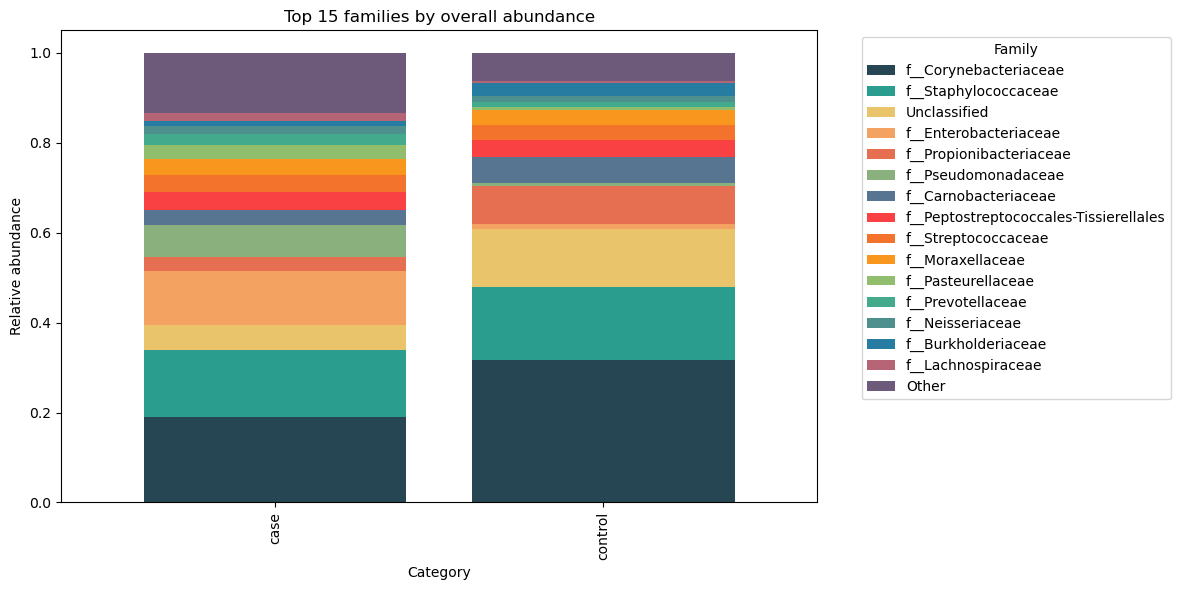

In [5]:
sample_to_category = merged_meta.set_index('Sample ID')['Category']
rel_abu = X.T.loc[:, lambda x: x.columns.get_level_values(1).isin(sample_to_category.index)].rename(columns=sample_to_category)
family = rel_abu.index.str.split(';').str[4]

# Overall family abundance
rel_abu_by_category = rel_abu.sum(axis=1).groupby(family).sum()
rel_abu_by_category /= rel_abu_by_category.sum()
rel_abu_by_category = rel_abu_by_category.sort_values(ascending=False)
top15 = rel_abu_by_category.head(15).index

top3 = ['f__Enterobacteriaceae', 'f__Staphylococcaceae', 'f__Corynebacteriaceae']
print(f"Abundance of top 3: {rel_abu_by_category.loc[top3].sum():.3f}")

# Family abundance by case/control
plot_df = rel_abu.groupby(axis=1, level=1).sum().groupby(family).sum()
plot_df /= plot_df.sum()
plot_df = plot_df.groupby(plot_df.index.where(plot_df.index.isin(top15), 'Other')).sum()
plot_df = plot_df.reindex([*top15, 'Other'], fill_value=0).rename(index={'__': 'Unclassified'})

palette = ["#264653", "#2A9D8F", "#E9C46A", "#F4A261", "#E76F51", "#8AB17D", "#577590", "#F94144",
           "#F3722C", "#F8961E", "#90BE6D", "#43AA8B", "#4D908E", "#277DA1", "#B56576", "#6D597A"]

ax = plot_df.T.plot(kind='bar', stacked=True, figsize=(12, 6), width=0.8, color=palette)
ax.set(xlabel='Category', ylabel='Relative abundance', title='Top 15 families by overall abundance')
ax.legend(title='Family', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout(); plt.show()

---
Genus-level information

Sample ID
case       0.462142
control    0.536903
dtype: float64
Overall relative abundance of target genera: 0.489
         count      mean    median       std
group                                       
case      1065  0.462142  0.450263  0.353515
control    589  0.536903  0.597460  0.321641
Mann-Whitney U = 348414.5, P = 0.0001852


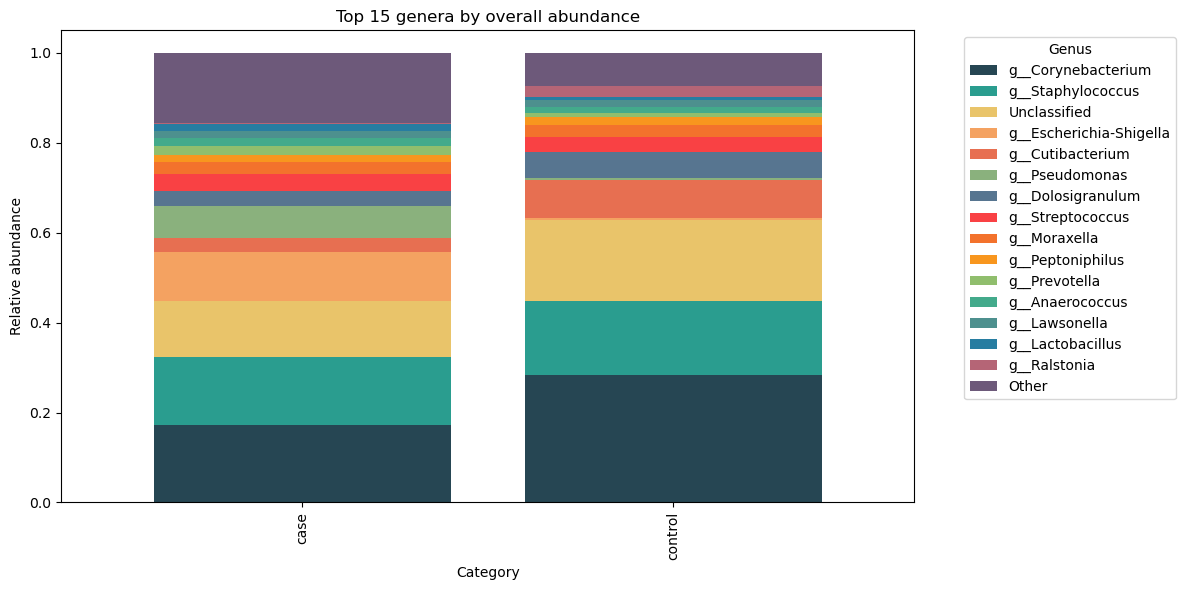

In [6]:
target_genera = ['g__Corynebacterium', 'g__Staphylococcus', 'g__Escherichia-Shigella', 'g__Cutibacterium']

# Keep relevant samples
rel_abu = X.T.loc[:, lambda x: x.columns.get_level_values(1).isin(sample_to_category.index)]
genus = rel_abu.index.str.split(';').str[5]

# Case/control relative abundance
rel_abu_case_control = rel_abu.rename(columns=sample_to_category).groupby(axis=1, level=1).sum()
rel_abu_case_control['Genus'] = genus
rel_abu_case_control = rel_abu_case_control.groupby('Genus').sum()
rel_abu_case_control = rel_abu_case_control.div(rel_abu_case_control.sum(axis=0), axis=1)
print(rel_abu_case_control.loc[target_genera].sum())

# Overall relative abundance
rel_abu_overall = rel_abu.sum(axis=1).to_frame('abundance')
rel_abu_overall['Genus'] = genus
rel_abu_overall = rel_abu_overall.groupby('Genus').sum()
rel_abu_overall = rel_abu_overall.div(rel_abu_overall.sum(axis=0), axis=1)
print(f"Overall relative abundance of target genera: {rel_abu_overall.loc[target_genera].sum().iloc[0]:.3f}")

# Mann-Whitney U test
rel_abu.columns = rel_abu.columns.get_level_values(1)
rel_abu['Genus'] = genus
genus_abu = rel_abu.groupby('Genus').sum()
genus_abu = genus_abu.div(genus_abu.sum(axis=0), axis=1)

four_genera = genus_abu.reindex(target_genera).fillna(0).sum(axis=0)
df_test = four_genera.rename('abundance').to_frame()
df_test['group'] = sample_to_category.loc[df_test.index]

case = df_test.loc[df_test['group'] == 'case', 'abundance']
control = df_test.loc[df_test['group'] == 'control', 'abundance']
u_stat, p_value = mannwhitneyu(control, case, alternative='two-sided')

print(df_test.groupby('group')['abundance'].agg(['count', 'mean', 'median', 'std']))
print(f'Mann-Whitney U = {u_stat:.1f}, P = {p_value:.4g}')

# Top 15 genera + Other
top15 = rel_abu_overall.sort_values('abundance', ascending=False).head(15).index
plot_df = rel_abu_case_control.copy()
plot_df['Genus_plot'] = plot_df.index.where(plot_df.index.isin(top15), 'Other')
plot_df = plot_df.groupby('Genus_plot').sum().reindex([*top15, 'Other'], fill_value=0)
plot_df = plot_df.rename(index={'__': 'Unclassified'})

# Stacked barplot
ax = plot_df.T.plot(kind='bar', stacked=True, figsize=(12, 6), width=0.8, color=palette)
ax.set(xlabel='Category', ylabel='Relative abundance', title='Top 15 genera by overall abundance')
ax.legend(title='Genus', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Fig 1.e-f

In [7]:
prevalence = (ra_raw > 0).sum(axis=1) / ra_raw.shape[1]
print(f'Initial shape: {ra_raw.shape}') # taxa, samples
n_gt_05 = (prevalence > 0.5).sum()
print(f"Taxa with prevalence > 0.5: {n_gt_05}")
print(f"Taxa with prevalence < 0.01: {(prevalence <= 0.01).sum()}")
print(f"Taxa with prevalence < 0.5: {(prevalence < 0.5).sum()}")
print(f"Taxa with prevalence >= 0.05: {(prevalence >= 0.05).sum()}")


Initial shape: (184, 1654)
Taxa with prevalence > 0.5: 8
Taxa with prevalence < 0.01: 0
Taxa with prevalence < 0.5: 176
Taxa with prevalence >= 0.05: 184


In [8]:
#This code calculates genus prevalence in case and control samples, identifies the top 8 most prevalent genera in each group, and compares which genera are unique to each top-8 list.
prev_cat = ra_raw.loc[:, ra_raw.columns.isin(sample_to_category.index)]
prev_cat= prev_cat.rename(columns=sample_to_category)
print((prev_cat>0).groupby(axis=1, level = 0).mean().sort_values('case', ascending = False).head(8))

case_prev = (prev_cat>0).groupby(axis=1, level = 0).mean().sort_values('case', ascending = False).head(8)
control_prev = (prev_cat>0).groupby(axis=1, level = 0).mean().sort_values('control', ascending = False).head(8)
case_g = [idx.split(';')[5] for idx in case_prev.index]
control_g = [idx.split(';')[5] for idx in control_prev.index]


                                                        case   control
OTU ID                                                                
d__Bacteria;p__Firmicutes;c__Bacilli;o__Staphyl...  0.889202  0.891341
d__Bacteria;p__Actinobacteriota;c__Actinobacter...  0.856338  0.837012
d__Bacteria;p__Actinobacteriota;c__Actinobacter...  0.726761  0.694397
d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactoba...  0.707981  0.578947
d__Bacteria;p__Firmicutes;c__Clostridia;o__Pept...  0.653521  0.597623
d__Bacteria;p__Proteobacteria;c__Gammaproteobac...  0.614085  0.415959
d__Bacteria;p__Firmicutes;c__Clostridia;o__Pept...  0.584977  0.584041
d__Bacteria;p__Proteobacteria;c__Gammaproteobac...  0.553991  0.477080


In [9]:
#overall prevalence
print((prev_cat>0).mean(axis =1).to_frame('prevalence').sort_values('prevalence', ascending = False).head(8))

                                                    prevalence
OTU ID                                                        
d__Bacteria;p__Firmicutes;c__Bacilli;o__Staphyl...    0.889964
d__Bacteria;p__Actinobacteriota;c__Actinobacter...    0.849456
d__Bacteria;p__Actinobacteriota;c__Actinobacter...    0.715236
d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactoba...    0.662031
d__Bacteria;p__Firmicutes;c__Clostridia;o__Pept...    0.633615
d__Bacteria;p__Firmicutes;c__Clostridia;o__Pept...    0.584643
d__Bacteria;p__Proteobacteria;c__Gammaproteobac...    0.543531
d__Bacteria;p__Proteobacteria;c__Gammaproteobac...    0.526602


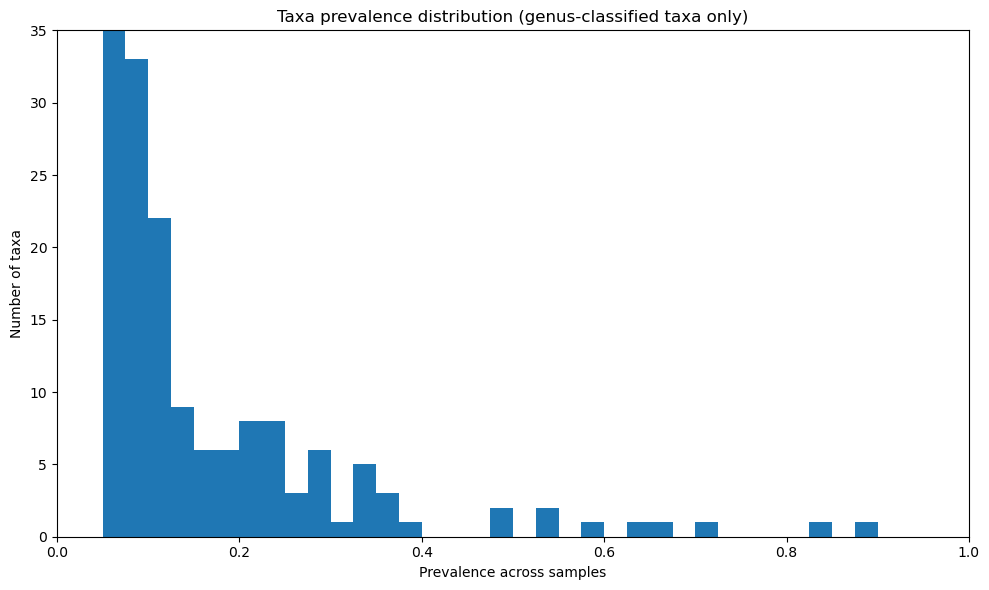

In [10]:
bins = np.linspace(0, 1, 41)  # 0, 0.05, ..., 1.0
counts, edges = np.histogram(prevalence, bins=bins)
centers = (edges[:-1] + edges[1:]) / 2

plt.figure(figsize=(10, 6))
plt.bar(centers, counts, width=np.diff(edges), align='center')

plt.xlabel("Prevalence across samples")
plt.ylabel("Number of taxa")
plt.xlim(0.0, 1)
plt.ylim(0,35)
plt.title("Taxa prevalence distribution (genus-classified taxa only)")
plt.tight_layout()
plt.show()

### Figure 1.g
- Run this code in R

In [11]:
# run Codes/Auxiliary_files/PCOA_analysis.R